# Módulo 30 - K-Means
**Atividade:**

Nesta tarefa, vamos explorar o algoritmo de clustering K-means aplicado a um contexto diferente do usual. Em vez de segmentar perfis de viajantes ou clientes de e-commerce, vamos usar dados biológicos para segmentar diferentes espécies de pinguins com base em características físicas. Esta abordagem destaca a versatilidade do K-means para diversas áreas além de vendas e marketing.

A base de dados utilizada é a penguins do pacote seaborn, que contém informações sobre três espécies de pinguins: Adelie, Chinstrap e Gentoo. As variáveis disponíveis incluem medições físicas dos pinguins coletadas na Antártica.

species: Espécie do pinguim (Adelie, Chinstrap, Gentoo)

island: Ilha onde o pinguim foi observado (Biscoe, Dream, Torgersen)

bill_length_mm: Comprimento do bico em milímetros

bill_depth_mm: Profundidade do bico em milímetros

flipper_length_mm: Comprimento da barbatana em milímetros

body_mass_g: Massa corporal em gramas

sex: Sexo do pinguim (Male, Female)

year: Ano em que a observação foi feita

In [22]:
import plotly.express as px
import plotly.graph_objects as go
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt

In [23]:
penguins = sns.load_dataset('penguins')

In [24]:
penguins

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


# 1 - Nesse exercício vocês devem verificar se temos variáveis missing, faltantes e excluir esses valores do dataset, também devem excluir as colunas com valores categóricos, que não utilizazam para o Kmeans.

In [25]:
penguins.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 24.9 KB


In [26]:
penguins.isna().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

In [27]:
penguins_limpo = penguins.dropna(subset=['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex'])

In [28]:
especies = penguins_limpo['species']

In [29]:
X = penguins_limpo.drop(columns=['species', 'island', 'sex'])

In [30]:
X

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,39.1,18.7,181.0,3750.0
1,39.5,17.4,186.0,3800.0
2,40.3,18.0,195.0,3250.0
4,36.7,19.3,193.0,3450.0
5,39.3,20.6,190.0,3650.0
...,...,...,...,...
338,47.2,13.7,214.0,4925.0
340,46.8,14.3,215.0,4850.0
341,50.4,15.7,222.0,5750.0
342,45.2,14.8,212.0,5200.0


# 2 - Visualize a análise descritiva dos seus dados utilizando a função vista em aula pairplot. É possível já identificar possíveis agrupamentos? Se sim, quantos?

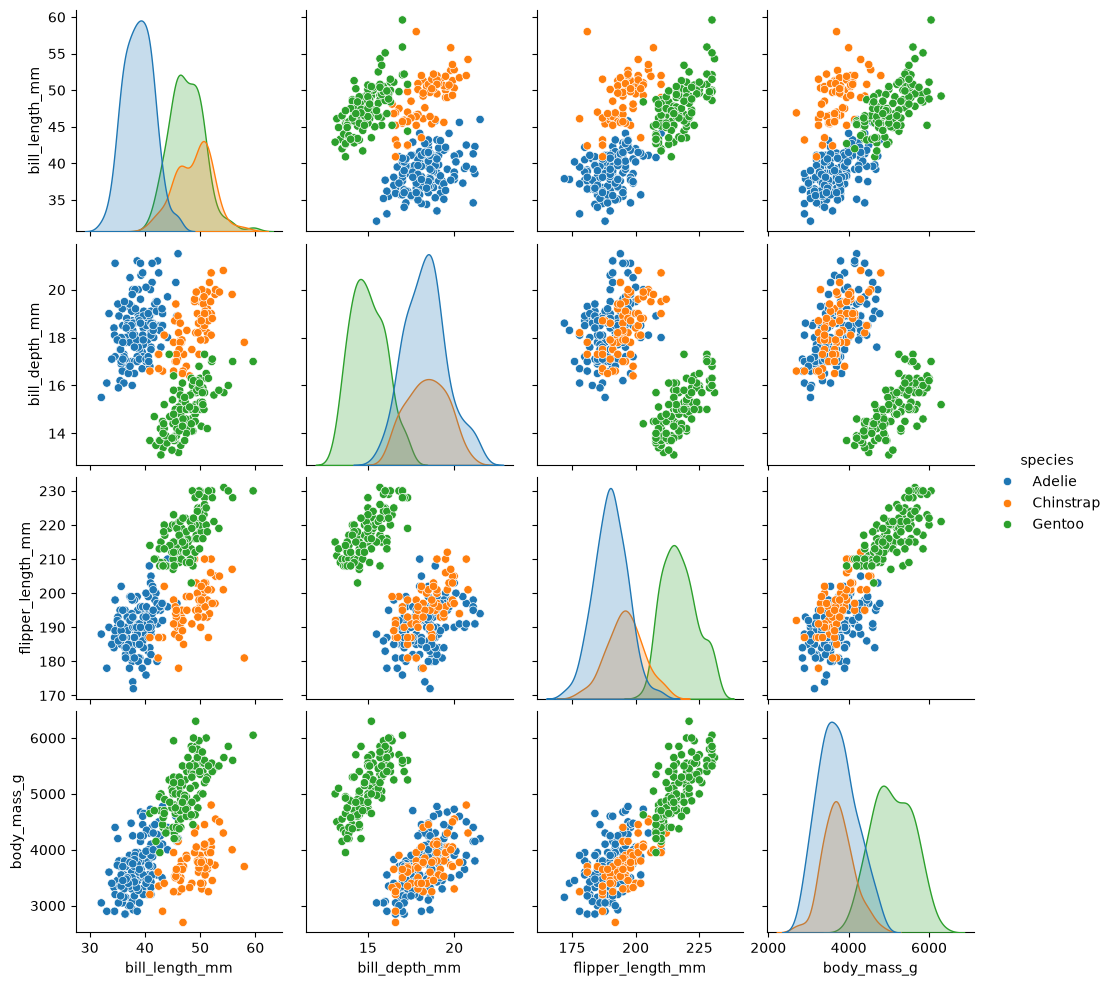

In [31]:
sns.pairplot(penguins_limpo, hue='species')
plt.show()

In [32]:
'''
Existem nuvens de dados separadas de forma mais distinta em alguns apres de dados como por exemplo em 
flipper_length_mm e bill_length_mm
E há alguns grupos que possuem sobreposição de grupos principalmente associados a variável body_mass_g
'''

'\nExistem nuvens de dados separadas de forma mais distinta em alguns apres de dados como por exemplo em \nflipper_length_mm e bill_length_mm\nE há alguns grupos que possuem sobreposição de grupos principalmente associados a variável body_mass_g\n'

# 3 - Realize a padronização dos dados e visualize os dados.

In [33]:
scaler = StandardScaler()
X_padronizado = scaler.fit_transform(X)

In [34]:
X_padronizado

array([[-0.89604189,  0.7807321 , -1.42675157, -0.56847478],
       [-0.82278787,  0.11958397, -1.06947358, -0.50628618],
       [-0.67627982,  0.42472926, -0.42637319, -1.1903608 ],
       ...,
       [ 1.17338426, -0.74499437,  1.50292796,  1.91906927],
       [ 0.22108196, -1.20271231,  0.78837197,  1.23499466],
       [ 1.08181673, -0.54156417,  0.85982757,  1.48374906]],
      shape=(333, 4))

In [35]:
X_padronizado_df = pd.DataFrame(
    X_padronizado,
    columns= ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
)

In [36]:
X_padronizado_df.describe().round(2)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,333.00,333.00,333.00,333.00
mean,0.00,0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-2.18,-2.07,-2.07,-1.87
25%,-0.82,-0.80,-0.78,-0.82
50%,0.09,0.07,-0.28,-0.20
75%,0.84,0.78,0.86,0.71
max,2.86,2.20,2.15,2.60


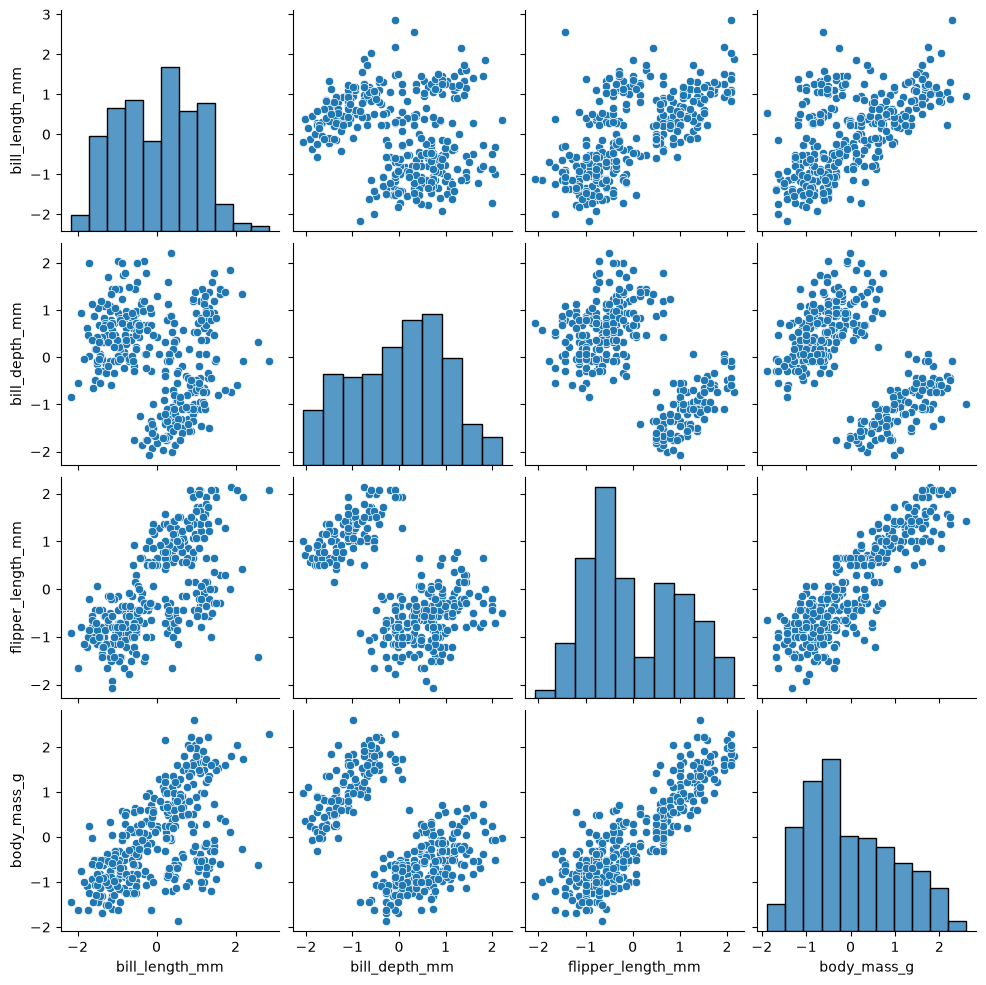

In [37]:
sns.pairplot(X_padronizado_df)

# 4 - Aplique o algoritmo do k means escolhendo o numero de clusters como igual a 3, que é que a quantidade de espécies que temos na base.

In [38]:
modelo = KMeans(
    n_clusters= 3,
    random_state=42,
    n_init=10
)

clusters = modelo.fit_predict(X_padronizado_df)

In [39]:
resultado = penguins_limpo.copy()
resultado['cluster'] = clusters

In [40]:
pd.crosstab(resultado['species'], resultado['cluster'])

cluster,0,1,2
species,,,
Adelie,124,0,22
Chinstrap,5,0,63
Gentoo,0,119,0


In [41]:
print(X_padronizado_df.shape)
print(penguins_limpo.shape)

(333, 4)
(333, 7)


# 5 - Construa pelo 2 matriz de dispersão como realizada em aula indicando os pontos e centroides.

**Comece usando x='bill_length_mm' e y='bill_depth_mm' para analisar o primeiro gráfico e em seguida escolha outras variaveis para o segundo.**

In [42]:
modelo.cluster_centers_

array([[-1.04680889,  0.48662566, -0.88169491, -0.7627539 ],
       [ 0.65475809, -1.10270671,  1.16246305,  1.10121078],
       [ 0.67202511,  0.80526339, -0.28934658, -0.38410387]])

In [43]:
centroides_originais = scaler.inverse_transform(modelo.cluster_centers_)

In [44]:
print(X_padronizado_df.shape)
print(modelo.cluster_centers_.shape)
print(centroides_originais.shape)

(333, 4)
(3, 4)
(3, 4)


In [47]:
centroides_df = pd.DataFrame(
    centroides_originais,
    columns = X_padronizado_df.columns
)
centroides_df

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,38.276744,18.121705,188.627907,3593.798450
1,47.568067,14.996639,217.235294,5092.436975
2,47.662353,18.748235,196.917647,3898.235294


In [49]:
df_clusters = pd.DataFrame({
    'bill_length_mm': penguins_limpo['bill_length_mm'],
    'bill_depth_mm': penguins_limpo['bill_depth_mm'],
    'cluster': clusters.astype(str)
})

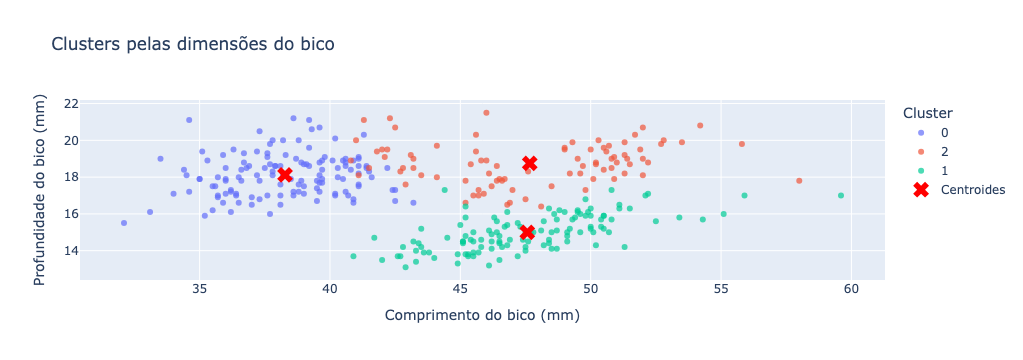

In [54]:
fig = px.scatter(
    df_clusters,
    x='bill_length_mm',
    y='bill_depth_mm',
    color='cluster',
    opacity=0.7,
    title='Clusters pelas dimensões do bico'
)

fig.add_scatter(
    x=centroides_df['bill_length_mm'],
    y=centroides_df['bill_depth_mm'],
    mode='markers',
    marker=dict(color='red', symbol='x', size=14),
    name='Centroides'
)

fig.update_layout(
    xaxis_title='Comprimento do bico (mm)',
    yaxis_title='Profundidade do bico (mm)',
    legend_title='Cluster'
)

fig.show()

In [57]:
df_clusters = pd.DataFrame({
    'flipper_length_mm': penguins_limpo['flipper_length_mm'],
    'body_mass_g': penguins_limpo['body_mass_g'],
    'cluster': clusters.astype(str)
})

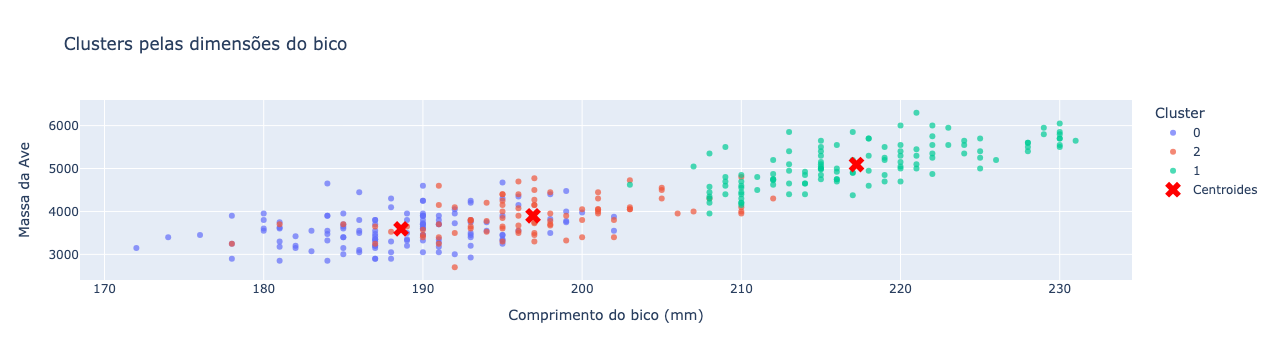

In [58]:
fig = px.scatter(
    df_clusters,
    x='flipper_length_mm',
    y='body_mass_g',
    color='cluster',
    opacity=0.7,
    title='Clusters pelas dimensões do bico'
)

fig.add_scatter(
    x=centroides_df['flipper_length_mm'],
    y=centroides_df['body_mass_g'],
    mode='markers',
    marker=dict(color='red', symbol='x', size=14),
    name='Centroides'
)

fig.update_layout(
    xaxis_title='Comprimento do bico (mm)',
    yaxis_title='Massa da Ave',
    legend_title='Cluster'
)

fig.show()

In [59]:
'''
para o primeiro gráfico demonstra categorias mais exclusivas com poucas sobreposições,
porém, para o segundo gráfico percebe-se uma acentuada sobreposição entre duas espécies 
além de um dos centroides bem distante
'''

'\npara o primeiro gráfico demonstra categorias mais exclusivas com poucas sobreposições,\nporém, para o segundo gráfico percebe-se uma acentuada sobreposição entre duas espécies \nalém de um dos centroides bem distante\n'

# 6 - Pesquise mais 3 utilidades de aplicações de algoritmos de clusterização e cite abaixo:

In [ ]:
'''
1) Análise de Redes Sociais
Mapeia conexões para descobrir comunidades digitais, grupos de interesse e líderes de opinião em plataformas sociais.
2) Detecção de Fraudes e Anomalias
Separa dados que não se encaixam em nenhum grupo padrão (usando métodos baseados em densidade como DBSCAN) 
para identificar transações bancárias suspeitas ou invasões de segurança.
3) Segmentação de Imagens e Visão Computacional
Divide pixels de uma imagem em regiões com cores ou texturas parecidas para separar objetos do fundo ou
identificar áreas em exames de imagem.
'''